# Vapour-Liquid Equilibrium -. Example: ternary mixture acetone-methanol-water

Speration processes that involves gas phase and liquid phase are governed by vapour-liquid equilibrium.

There are three cases of VLE problems:
* Bubble-point T calculation: Given liquid composition (xi) and pressure (P), determine the equilibrium temperature (T),
* Bubble-point P calculation: Given liquid composition (xi) and temperature (T), determine the equilibrium pressure (P),
* Dew-point T calculation: Given vapor composition (yi) and pressure (P), determine the equilibrium temperature (T),
* Dew-point P calculation: Given vapor composition (yi) and temperature (T), determine the equilibrium pressure (P).

In our applications, we usually assume the pressure to be constant, and then we can either either perform a bubble-T or a dew-T calculation. We will go ahead with bubble-T.

The governing set of conditions for the VLE are therefore:

1. VLE condition: Fugacities of each component must be equal in vapor and liquid phases
2. Ideal vapor assumption: Vapor phase fugacity coefficient = 1, simplifying the equilibrium
3. Bubble point formulation: Given liquid composition, solve for temperature and vapor composition
4. Degrees of freedom: With fixed pressure and given liquid composition, the system has 2 unknowns (T and vapor fractions) and 2 equations. However since these two are related (given T, y can be calculated and vice-versa, only one degree of freedom is present, e.g. the temperature)


Fugacity equality (general VLE condition):
\begin{equation*}
\hat{f}_i^V = \hat{f}_i^L
\end{equation*}

Vapor phase fugacity:
\begin{equation*}
\hat{f}_i^V = y_i \hat{\phi}_i P
\end{equation*}

Liquid phase fugacity:
\begin{equation*}
\hat{f}_i^L = x_i \hat{\gamma}_i P_i^{sat}
\end{equation*}

VLE equilibrium (ideal vapor phase):
\begin{equation*}
y_i = x_i \hat{\gamma}_i \frac{P_i^{sat}}{P}
\end{equation*}

Vapor composition normalization:
\begin{equation*}
\sum_i y_i = 1
\end{equation*}



Let us try the complete workflow:
1. define e.g. acetone-methanol system
2. calculate the pure component properties
3. determine the Antoine coefficients
4. perform the VLE routine

In [1]:
# imports to enable the notebook to access the src folder
import sys
import os
sys.path.append(os.path.dirname(os.getcwd()))

# import the necessary packages
from src.molecules import StructuralValidator
from src.pure import PropertyCalculator
from src.pure import AntoineCalculator
from src.data import load_unifac_data
from src.mixture.unifac.pyomo_vle import pyo_vle
import numpy as np
import matplotlib.pyplot as plt


In [4]:
# step1: define the compounds
mixture = { 'ethanol': {'CH3':1, 'CH2':1, 'OH':1},
            #'acetone': {'CH3':1, 'CH3CO':1},
           #'methanol': {'CH3OH':1},
           'water': {'H2O':1}
           #'E': {'CH2': 3, 'HCO': 1, 'CH3COO': 1}
           #'E': {'CH3':1, 'CH2':2, 'CH3CO':1, 'CH2O':1}
           #'E': {'CH3':3, 'CH':1, 'CH2COO':1}
           }
# validate the structures
validator = StructuralValidator()
validator.validate(mixture)

{'ethanol': False, 'water': False}

In [3]:
# step2: calculate the required properties
prop_list = ['tc', 'pc', 'tb', 'ac']
pure_calc = PropertyCalculator()
pure_props = pure_calc.calculate(mixture, prop_list)
# fix the properties of acetone
pure_props['acetone']['tc'] = 508.1
pure_props['acetone']['pc'] = 48.0
pure_props['acetone']['tb'] = 329.3
pure_props

{'acetone': {'tc': 508.1, 'pc': 48.0, 'tb': 329.3, 'ac': 0.33226923286882887},
 'methanol': {'tc': 513.0000000000005,
  'pc': 80.99999999999997,
  'tb': 337.84999999999985,
  'ac': 0.5639909999999987},
 'E': {'tc': 634.7973367783701,
  'pc': 34.02169541524059,
  'tb': 454.7565664246498,
  'ac': 0.6917322651257258}}

In [4]:
# step3: calculate the Antoine coefficients
antoine_params_ini = {}
antoine_params = {}
antoine_calc = AntoineCalculator()
for compound, props in pure_props.items():
    results = antoine_calc.calculate_antoine_parameters(mixture, critical_properties=props, method='acentric_factor')
    print('optimization results was', results['termination_condition'] )
    antoine_params[compound] = {}
    antoine_params_ini[compound] = {}
    # antoine_params_ini[compound]['A'] = results['A0']
    # antoine_params_ini[compound]['B'] = results['B0']
    # antoine_params_ini[compound]['C'] = results['C0']
    antoine_params[compound]['A'] = results['A']
    antoine_params[compound]['B'] = results['B']
    antoine_params[compound]['C'] = results['C']
print(antoine_params_ini)
print(antoine_params)

Characteristic points (T [K], P [bar]): (329.3, 1.01325), (355.67, 2.2334282469263593), (508.1, 48.0)
optimization results was optimal
Characteristic points (T [K], P [bar]): (337.84999999999985, 1.01325), (359.1000000000003, 2.210517812748135), (513.0000000000005, 80.99999999999997)
optimization results was optimal
Characteristic points (T [K], P [bar]): (454.7565664246498, 1.01325), (444.35813574485906, 0.69186870539733), (634.7973367783701, 34.02169541524059)
optimization results was optimal
{'acetone': {}, 'methanol': {}, 'E': {}}
{'acetone': {'A': 5.105487152022129, 'B': 1863.5123768521207, 'C': 36.111024354679266}, 'methanol': {'A': 5.253881516250653, 'B': 1616.1411202945164, 'C': -29.905956718707568}, 'E': {'A': 3.454335513250043, 'B': 782.23034268757, 'C': -227.93233180194986}}


In [5]:
# step4: perform the vle

# define number of data points
n_data = 100
# set composition
# generate all binary combinations for ternary system
# x1-x2 binary (x3=0)
x0 = 0.0
xf = 1-x0
x1_12 = np.linspace(x0, xf, n_data)
x2_12 = 1 - x1_12
x3_12 = np.zeros(n_data)

# x1-x3 binary (x2=0)
x1_13 = np.linspace(x0, xf, n_data)
x2_13 = np.zeros(n_data)
x3_13 = 1 - x1_13

# x2-x3 binary (x1=0)
x1_23 = np.zeros(n_data)
x2_23 = np.linspace(x0, xf, n_data)
x3_23 = 1 - x2_23

# combine all binary combinations
x = np.vstack([
    np.column_stack([x1_12, x2_12, x3_12]),
    np.column_stack([x1_13, x2_13, x3_13]),
    np.column_stack([x1_23, x2_23, x3_23])
])
# provide nitial guess for temperature

# Extract boiling points for each compound
tb_values = [pure_props[compound]['tb'] for compound in mixture.keys()]
tb1, tb2, tb3 = tb_values  # assuming 3 components
# Create T0 for each binary combination
# x1-x2 binary: T ranges from tb2 (x1=0, x2=1) to tb1 (x1=1, x2=0)
T0_12 = np.linspace(tb2, tb1, n_data)

# x1-x3 binary: T ranges from tb3 (x1=0, x3=1) to tb1 (x1=1, x3=0)
T0_13 = np.linspace(tb3, tb1, n_data)

# x2-x3 binary: T ranges from tb3 (x2=0, x3=1) to tb2 (x2=1, x3=0)
T0_23 = np.linspace(tb3, tb2, n_data)

# Combine all T0 values
T0 = np.concatenate([T0_12, T0_13, T0_23])
# Load all UNIFAC parameters
rk_data, qk_data, interaction_data = load_unifac_data()
# perform the VLE calculation
results, model = pyo_vle(x, T0, mixture, rk_data, qk_data, interaction_data, antoine_params, verbose=True)


Ipopt 3.14.13: halt_on_ampl_error=yes
max_iter=100000
tol=1e-06


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************

This is Ipopt version 3.14.13, running with linear solver MUMPS 5.2.1.

Number of nonzeros in equality constraint Jacobian...:   108858
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:    96324

Total number of variables............................:    26424
                     variables with only lower bounds:    23424
                variables with lower and upper bounds:     1200
                     variables with only upper bounds:        0
Total number of equality co

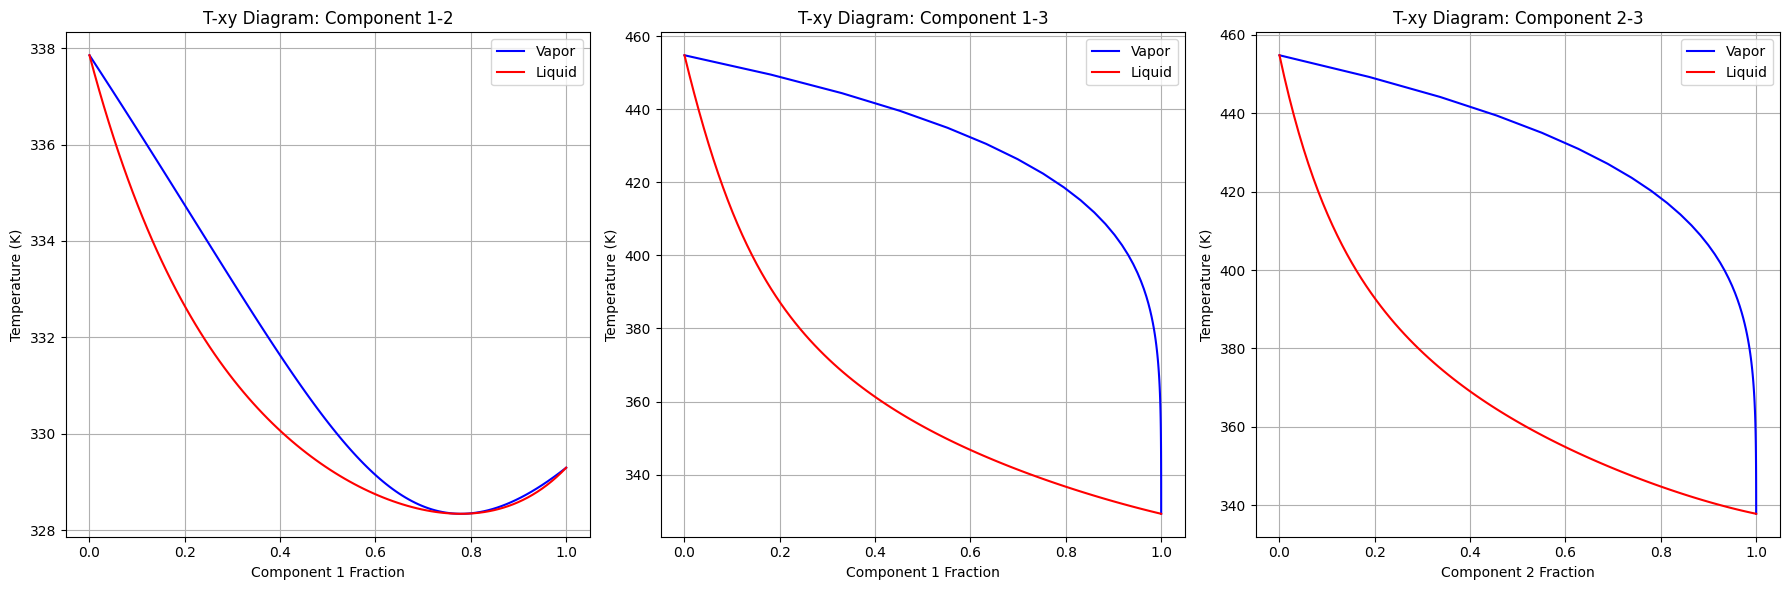

In [6]:
# step5: lets plot the results in T-xy diagram and inspect the gamma values
import matplotlib.pyplot as plt

# Extract results
# retrieving the solutions
gamma_pyo = np.empty_like(x)
T_pyo = np.empty_like(T0)
y_pyo = np.empty_like(x)
psat_pyo = np.empty_like(x)

for i in model.gamma.keys():
    gamma_pyo[i] = model.gamma[i].value

for i in model.T.keys():
    T_pyo[i] = model.T[i].value

for i in model.y.keys():
    y_pyo[i] = model.y[i].value

for i in model.psat.keys():
    psat_pyo[i] = model.psat[i].value

# Create T-xy plots for all three binary combinations
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Component 1-2 diagram (first 100 points)
axes[0].plot(y_pyo[:n_data, 0], T_pyo[:n_data], 'b-', label='Vapor')
axes[0].plot(x[:n_data, 0], T_pyo[:n_data], 'r-', label='Liquid')
axes[0].set_ylabel('Temperature (K)')
axes[0].set_xlabel('Component 1 Fraction')
axes[0].set_title('T-xy Diagram: Component 1-2')
axes[0].legend()
axes[0].grid()

# Component 1-3 diagram (points 100-200)
axes[1].plot(y_pyo[n_data:2*n_data, 0], T_pyo[n_data:2*n_data], 'b-', label='Vapor')
axes[1].plot(x[n_data:2*n_data, 0], T_pyo[n_data:2*n_data], 'r-', label='Liquid')
axes[1].set_ylabel('Temperature (K)')
axes[1].set_xlabel('Component 1 Fraction')
axes[1].set_title('T-xy Diagram: Component 1-3')
axes[1].legend()
axes[1].grid()

# Component 2-3 diagram (points 200-300)
axes[2].plot(y_pyo[2*n_data:3*n_data, 1], T_pyo[2*n_data:3*n_data], 'b-', label='Vapor')
axes[2].plot(x[2*n_data:3*n_data, 1], T_pyo[2*n_data:3*n_data], 'r-', label='Liquid')
axes[2].set_ylabel('Temperature (K)')
axes[2].set_xlabel('Component 2 Fraction')
axes[2].set_title('T-xy Diagram: Component 2-3')
axes[2].legend()
axes[2].grid()

plt.tight_layout()
plt.show()

# 

we will now make a test for the azeotrope detection according to the following equations.

\begin{equation*}
\log \gamma_A \cdot P_A^{\text{sat}}\big|_{x_A=0} - \log \gamma_B \cdot P_B^{\text{sat}}\big|_{x_A=1}
\end{equation*}

lets check the charachtertic points of the vle

In [7]:
x[[0, n_data-1,n_data]]

array([[0., 1., 0.],
       [1., 0., 0.],
       [0., 0., 1.]])

In [8]:
# is there azeotrope between acetone and methanol?
print(f"there is azeotrope between acetone and methanol: {np.log(gamma_pyo[0,0]*psat_pyo[0,0]) * (- np.log(gamma_pyo[n_data-1,1]*psat_pyo[n_data-1,1])) }")
print(f"there is azeotrope between acetone and water: {np.log(gamma_pyo[-1,0]*psat_pyo[-1,0]) * (- np.log(gamma_pyo[n_data-1,2]*psat_pyo[n_data-1,2])) }")
print(f"there is azeotrope between methanol and water: {np.log(gamma_pyo[-1,1]*psat_pyo[-1,1]) * (- np.log(gamma_pyo[0,2]*psat_pyo[0,2])) }")

there is azeotrope between acetone and methanol: -0.274055529769952
there is azeotrope between acetone and water: 9.110972948445827
there is azeotrope between methanol and water: 0.12182058798640483


Now lets check for the mscibility between water and the two other components according to the two relations:

\begin{equation*}
\frac{\Delta G_{\text{mix}}}{RT} = \sum_i x_i \log(\gamma_i) + \sum_i x_i \log(x_i) \leq 0
\end{equation*}

\begin{equation*}
  \frac{\partial^2 \left(\frac{\Delta G^{mix}}{RT}\right)}{\partial x_i^2} = \frac{\Delta G^{mix}}{RT}\bigg|_{x_{p+1,i}} - 2 \frac{\Delta
  G^{mix}}{RT}\bigg|_{x_{p,i}} + \frac{\Delta G^{mix}}{RT}\bigg|_{x_{p-1,i}} \geq 0
\end{equation*}

In [9]:
# miscibility between acetone and water
Gmix = (np.sum(x * np.log(gamma_pyo), axis=1) +
                np.sum(np.ma.log(x).filled(0) * x, axis=1))
Gmix_13 = Gmix[n_data:2*n_data]
Gmix_23 = Gmix[2*n_data:]
# calculate 2nd derivatives
Gmix_13_2nd = np.diff(np.diff(Gmix_13))
Gmix_23_2nd = np.diff(np.diff(Gmix_23))
# miscibility between methanol and water
print(f"mixture of acetone and water is miscible: {np.all(Gmix_13 <= 0) and np.all(Gmix_13_2nd >= 0)}")
print(f"mixture of methanol and water is miscible: {np.all(Gmix_23 <= 0) and np.all(Gmix_23_2nd >= 0)}")

mixture of acetone and water is miscible: True
mixture of methanol and water is miscible: True


A final element is to caulcate the relative volatility, selecivity and capacity at infinite dilution

\begin{equation*}
\alpha_{A,B}^{\infty} = \left(\frac{K_A^{\infty}}{K_B^{\infty}}\right)_E = \left(\frac{\gamma_A^{\infty}}{P^*_A} * \frac{\gamma_B^{\infty}}{P^*_B} \right)_E  
\end{equation*}


\begin{equation*}
S_{A,B}^{\infty} = \left(\frac{\gamma_A^{\infty}}{\gamma_B^{\infty}}\right)_E
\end{equation*}

\begin{equation*}
C_{B,E}^{\infty} = \left(\frac{1}{\gamma_B^{\infty}}\right)_E
\end{equation*}

\begin{equation*}
C_{B,E}^{\infty} * S_{A,B}^{\infty}
\end{equation*}

In [10]:
x[[0, n_data-1,n_data]]

array([[0., 1., 0.],
       [1., 0., 0.],
       [0., 0., 1.]])

In [11]:
# calculate the relative volatility
alpha = gamma_pyo[n_data,0]/psat_pyo[n_data,0] * gamma_pyo[n_data,1]/gamma_pyo[n_data,1]
alpha

np.float64(0.04815167074334731)

In [12]:
# calculate selectivity
S = gamma_pyo[n_data,0]/gamma_pyo[n_data,1]
S

np.float64(1.3066713575992999)

In [13]:
# calculate the capacity
C = 1/gamma_pyo[n_data,1]
C

np.float64(1.3317754573644607)

In [14]:
# calculating the product
S*C

np.float64(1.7401928448918482)